# Milestone 1 — Exploratory Data Analysis
## Breast Cancer Wisconsin (Diagnostic)

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)  
**Modul:** 9 — Statistik Deskriptif & Visualisasi Data

### Dataset
- **Nama:** Breast Cancer Wisconsin (Diagnostic)
- **Kaggle:** `uciml/breast-cancer-wisconsin-data`
- **Sumber asli:** UCI Machine Learning Repository, DOI `10.24432/C5DW2B`
- **Lisensi sumber asli:** CC BY 4.0
- **Ukuran:** 569 observasi, 30 fitur numerik + target diagnosis
- **Konteks:** fitur dihitung dari citra digital fine needle aspirate (FNA) massa payudara dan menggambarkan karakteristik inti sel.
- **Target:** diagnosis **Benign** atau **Malignant**

> Untuk reproducibility tanpa API Kaggle, notebook memuat packaged copy dataset yang sama dari `sklearn.datasets.load_breast_cancer`.

### Pertanyaan EDA
1. Fitur ukuran tumor apa yang paling berbeda antara diagnosis benign dan malignant?
2. Fitur apa yang memiliki korelasi kuat sehingga berpotensi redundan?
3. Bagaimana distribusi dan outlier fitur utama berbeda berdasarkan diagnosis?


## Step 1 — Load & Inspect

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
df = data.frame.copy()
df["Diagnosis"] = df["target"].map({0: "Malignant", 1: "Benign"})

print(f"Shape: {df.shape[0]} baris x {df.shape[1]} kolom")
print("\nTarget:")
print(df["Diagnosis"].value_counts())
df.head()

Shape: 569 baris x 32 kolom

Target:
Diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,Malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,Malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,Malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,Malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,Malignant


In [2]:
print("=== DTYPES ===")
print(df.dtypes.value_counts())
print("\n=== SAMPLE COLUMNS ===")
print(df.columns.tolist()[:12])
print("\n=== DESCRIBE ===")
display(df.drop(columns=["Diagnosis"]).describe().T.head(10).round(3))

=== DTYPES ===
float64    30
int64       1
object      1
Name: count, dtype: int64

=== SAMPLE COLUMNS ===
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error']

=== DESCRIBE ===


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


## Step 2 — Missing Values & Duplicate

In [3]:
print("Total missing values :", int(df.isna().sum().sum()))
print("Duplicate rows       :", int(df.duplicated().sum()))
print("\nMissing per column (hanya yang >0):")
missing = df.isna().sum()
print(missing[missing > 0])

Total missing values : 0
Duplicate rows       : 0

Missing per column (hanya yang >0):
Series([], dtype: int64)


## Step 3 — Central Tendency

In [4]:
focus = ["mean radius", "mean texture", "mean area", "mean concavity", "worst radius", "worst area"]

central = pd.DataFrame({
    "Mean": df[focus].mean(),
    "Median": df[focus].median(),
    "Mode": df[focus].mode().iloc[0],
    "Skewness": df[focus].skew()
}).round(3)

display(central)

,Mean,Median,Mode,Skewness
mean radius,14.127,13.370,12.34,0.942
mean texture,19.290,18.840,14.93,0.650
mean area,654.889,551.100,512.20,1.646
mean concavity,0.089,0.062,0.00,1.401
worst radius,16.269,14.970,12.36,1.103
worst area,880.583,686.500,284.40,1.859


## Step 4 — Dispersion

In [5]:
dispersion = pd.DataFrame(index=focus)
dispersion["Range"] = df[focus].max() - df[focus].min()
dispersion["Variance"] = df[focus].var()
dispersion["Std Dev"] = df[focus].std()
dispersion["IQR"] = df[focus].quantile(0.75) - df[focus].quantile(0.25)
dispersion["CV (%)"] = df[focus].std() / df[focus].mean() * 100

display(dispersion.round(3))

,Range,Variance,Std Dev,IQR,CV (%)
mean radius,21.129,12.419,3.524,4.080,24.945
mean texture,29.570,18.499,4.301,5.630,22.297
mean area,2357.500,123843.554,351.914,362.400,53.736
mean concavity,0.427,0.006,0.080,0.101,89.775
worst radius,28.110,23.360,4.833,5.780,29.708
worst area,4068.800,324167.385,569.357,568.700,64.657


## Step 5 — Univariate Visualization (minimal 3)

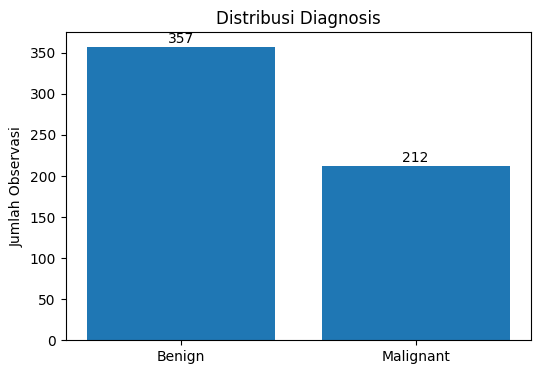

In [6]:
# Univariat 1: frekuensi diagnosis
counts = df["Diagnosis"].value_counts()
plt.figure(figsize=(6,4))
plt.bar(counts.index, counts.values)
plt.title("Distribusi Diagnosis")
plt.ylabel("Jumlah Observasi")
for i, v in enumerate(counts.values):
    plt.text(i, v + 5, str(v), ha="center")
plt.show()

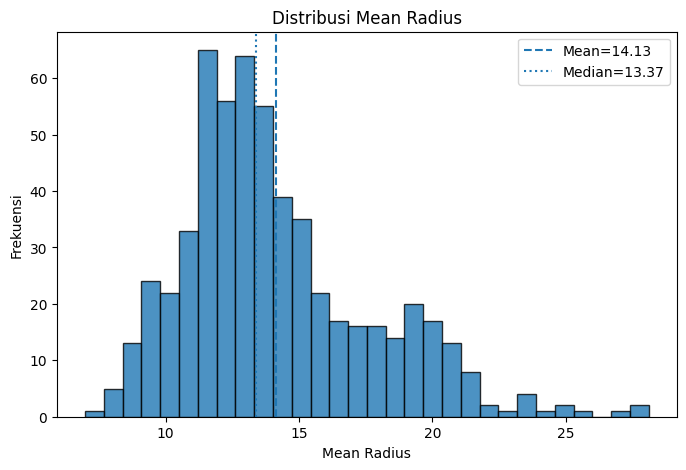

In [7]:
# Univariat 2: histogram mean radius
plt.figure(figsize=(8,5))
plt.hist(df["mean radius"], bins=30, edgecolor="black", alpha=0.8)
plt.axvline(df["mean radius"].mean(), linestyle="--", label=f"Mean={df['mean radius'].mean():.2f}")
plt.axvline(df["mean radius"].median(), linestyle=":", label=f"Median={df['mean radius'].median():.2f}")
plt.title("Distribusi Mean Radius")
plt.xlabel("Mean Radius")
plt.ylabel("Frekuensi")
plt.legend()
plt.show()

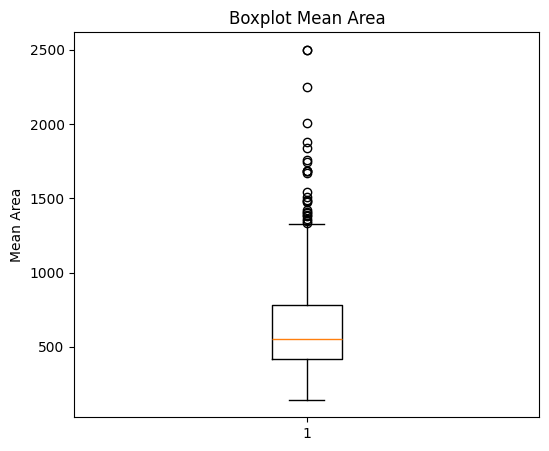

Outlier mean area (IQR method): 25


In [8]:
# Univariat 3: boxplot mean area
plt.figure(figsize=(6,5))
plt.boxplot(df["mean area"], vert=True)
plt.title("Boxplot Mean Area")
plt.ylabel("Mean Area")
plt.show()

q1 = df["mean area"].quantile(0.25)
q3 = df["mean area"].quantile(0.75)
iqr = q3 - q1
n_out = ((df["mean area"] < q1 - 1.5*iqr) | (df["mean area"] > q3 + 1.5*iqr)).sum()
print("Outlier mean area (IQR method):", int(n_out))

## Step 6 — Bivariate Visualization (minimal 3)

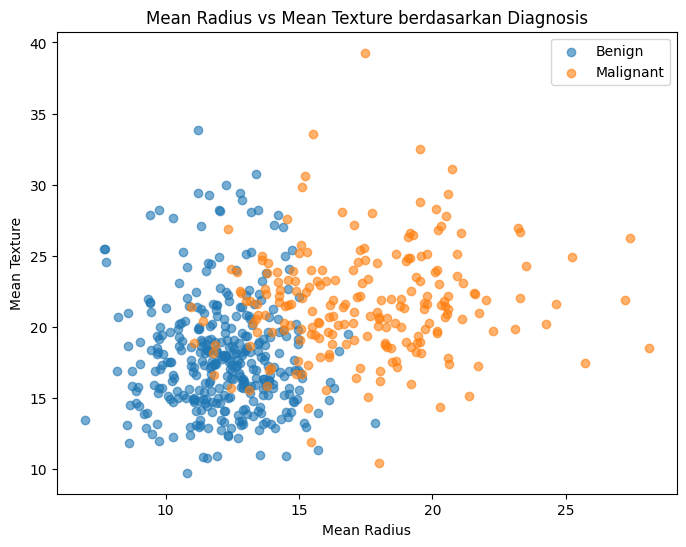

In [9]:
# Bivariat 1: mean radius vs mean texture berdasarkan diagnosis
plt.figure(figsize=(8,6))
for label, group in df.groupby("Diagnosis"):
    plt.scatter(group["mean radius"], group["mean texture"], alpha=0.6, label=label)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Mean Radius vs Mean Texture berdasarkan Diagnosis")
plt.legend()
plt.show()

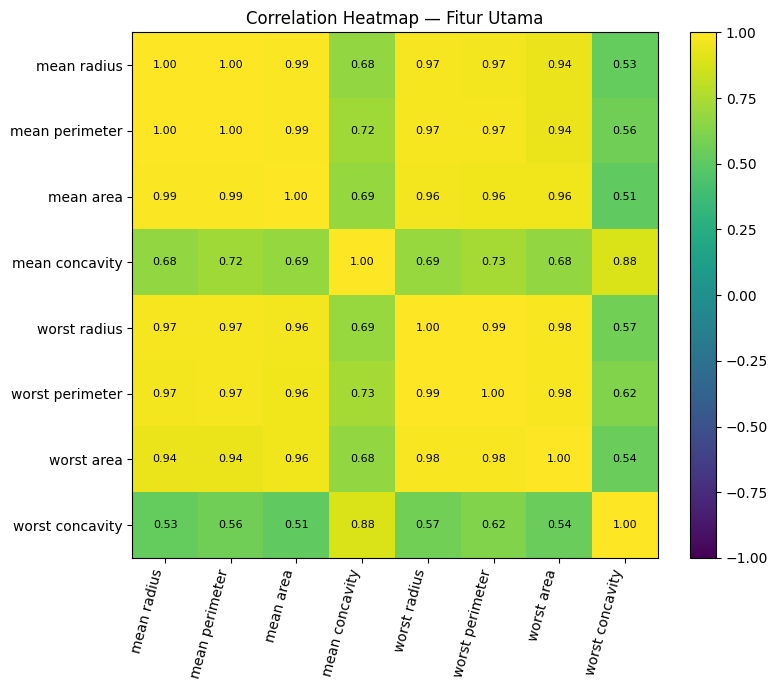

In [10]:
# Bivariat 2: correlation heatmap sederhana dengan matplotlib
corr_features = ["mean radius", "mean perimeter", "mean area", "mean concavity",
                 "worst radius", "worst perimeter", "worst area", "worst concavity"]
corr = df[corr_features].corr()

plt.figure(figsize=(9,7))
im = plt.imshow(corr, vmin=-1, vmax=1)
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr_features)), corr_features, rotation=75, ha="right")
plt.yticks(range(len(corr_features)), corr_features)
plt.title("Correlation Heatmap — Fitur Utama")
for i in range(len(corr_features)):
    for j in range(len(corr_features)):
        plt.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.show()

/tmp/ipykernel_1555/3460442971.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=["Benign", "Malignant"])


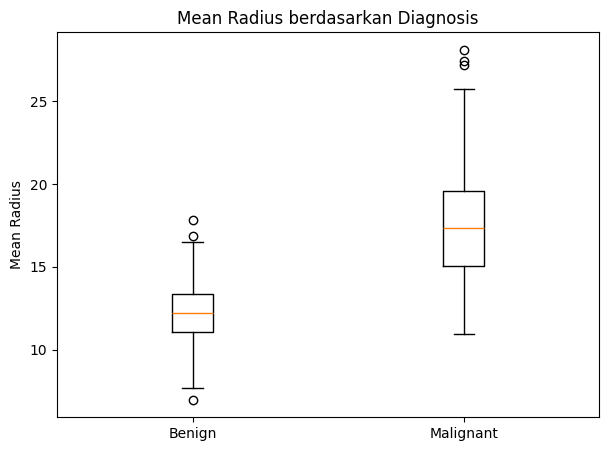

             mean  median    std
Diagnosis                       
Benign     12.147  12.200  1.781
Malignant  17.463  17.325  3.204


In [11]:
# Bivariat 3: grouped boxplot mean radius per diagnosis
groups = [df.loc[df["Diagnosis"]=="Benign", "mean radius"],
          df.loc[df["Diagnosis"]=="Malignant", "mean radius"]]
plt.figure(figsize=(7,5))
plt.boxplot(groups, labels=["Benign", "Malignant"])
plt.title("Mean Radius berdasarkan Diagnosis")
plt.ylabel("Mean Radius")
plt.show()

print(df.groupby("Diagnosis")["mean radius"].agg(["mean","median","std"]).round(3))

## Step 7 — Interactive Plotly Dashboard

In [12]:
# Interactive chart 1
fig1 = px.scatter(
    df, x="mean radius", y="mean texture",
    color="Diagnosis", size="mean area",
    hover_data=["worst radius", "worst area"],
    title="Interactive: Radius vs Texture"
)
fig1.show()

In [13]:
# Interactive chart 2
fig2 = px.histogram(
    df, x="mean area", color="Diagnosis",
    marginal="box", barmode="overlay",
    title="Interactive: Distribusi Mean Area per Diagnosis"
)
fig2.show()

## Insight dengan Evidence

1. **Komposisi kelas tidak seimbang sempurna:** terdapat **357 benign (62.7%)** dan **212 malignant (37.3%)**. Evaluasi lanjutan perlu mempertimbangkan class balance.
2. **Ukuran tumor berbeda jelas antar diagnosis:** rata-rata `mean radius` malignant sekitar **17.46**, sedangkan benign sekitar **12.15**. `worst radius` juga jauh lebih tinggi pada malignant (**21.14 vs 13.38**).
3. **`mean area` sangat right-skewed:** mean sekitar **654.9** sedangkan median **551.1**, dengan skewness sekitar **1.65**. Median/IQR lebih robust daripada hanya mean/std untuk menggambarkan fitur ini.
4. **Ada multikolinearitas kuat pada fitur ukuran:** korelasi `mean radius` dengan `mean area` sekitar **0.99**, dan `worst radius` dengan `worst area` sekitar **0.98**. Ini menunjukkan beberapa fitur membawa informasi yang sangat mirip.
5. **Fitur concavity memiliki variasi relatif besar:** CV `mean concavity` sekitar **89.8%**, menunjukkan heterogenitas yang tinggi antar observasi dan potensi daya pembeda diagnosis.


## Hipotesis untuk Milestone 2 (Modul 10)

1. **H1 — Mean Radius:** rata-rata `mean radius` pada kelompok malignant berbeda signifikan dari kelompok benign.
2. **H2 — Mean Texture:** rata-rata `mean texture` pada kelompok malignant berbeda signifikan dari kelompok benign.
3. **H3 — Mean Concavity:** rata-rata `mean concavity` pada kelompok malignant lebih tinggi daripada kelompok benign.

Hipotesis ini dapat diuji pada Modul 10 menggunakan uji yang sesuai setelah pengecekan asumsi distribusi dan varians.


## Checklist Milestone 1

- [x] Dataset ≥500 rows dan ≥5 kolom
- [x] Sumber, lisensi, dan konteks dijelaskan
- [x] Framework EDA 7 langkah lengkap
- [x] Minimal 6 visualisasi (3 univariat + 3 bivariat)
- [x] Interactive Plotly dashboard minimal 2 chart
- [x] 3–5 insight tertulis dengan evidence
- [x] 2–3 hipotesis untuk Milestone 2
- [x] README.md disiapkan
